# 🏆 Capstone Project: Reference Solution
**Agricultural market price forecasting for "Region B" (beans & potato)**

> ⚠️ Open this only **after** you have finished your own project. It shows *one* strong, honest workflow: not the only valid one.
> The aim of a good solution is **not** the lowest number; it is a *credible* comparison, correctly validated, with conclusions that match the evidence.

**Workflow:** data audit → cleaning → exploratory discovery → evaluation protocol → baselines & models → *development-period* comparison & model selection →
**one-shot** test on the 2024 hold-out → intervals → conclusions.

In [1]:
import sys; sys.path.append(".."); sys.path.append("../project")
import warnings
import statsmodels.tools.sm_exceptions
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from course_utils import *
from project_utils import *
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import STL

## 1 · Data audit
We load **only the training file**. The 2024 hold-out stays unopened until Section 7: no peeking, not even for plots.

In [2]:
raw = pd.read_csv("../project/data/project_market_train.csv", parse_dates=["date"])
print("rows:", len(raw), "| commodities:", raw.commodity.unique().tolist(), "| range:", raw.date.min().date(), "→", raw.date.max().date())
print("exact duplicate rows :", int(raw.duplicated().sum()))
print("missing values       :", raw.isna().sum()[lambda s: s > 0].to_dict())
for c, g in raw.drop_duplicates().groupby("commodity"):
    full = pd.date_range(g.date.min(), g.date.max(), freq="W-SUN")
    med = g.set_index("date").price.rolling(7, center=True, min_periods=3).median()
    r = (g.set_index("date").price / med)
    print(f"{c:<7} missing weeks: {len(full.difference(g.date))} | suspicious prices (ratio to rolling median >2 or <0.5): {int(((r > 2) | (r < 0.5)).sum())}")
raw.describe().round(1).T[["min", "50%", "max"]]

rows: 1140 | commodities: ['beans', 'potato'] | range: 2013-01-06 → 2023-12-31
exact duplicate rows : 2
missing values       : {'rainfall_mm': 6}
beans   missing weeks: 5 | suspicious prices (ratio to rolling median >2 or <0.5): 2
potato  missing weeks: 5 | suspicious prices (ratio to rolling median >2 or <0.5): 2


,min,50%,max
date,2013-01-06 00:00:00,2018-07-04 12:00:00,2023-12-31 00:00:00
price,2.6,84.5,1466.0
arrivals_tonnes,51.9,92.2,163.3
rainfall_mm,0.2,19.3,138.3
temp_c,19.9,24.8,31.0
exchange_rate,99.0,114.2,202.2
festival_flag,0.0,0.0,1.0


**Findings:** 2 duplicate rows; 5 missing weeks per commodity; 2 decimal-shift typos per commodity; a 3-week gap in rainfall (sensor outage). Also note `arrivals_tonnes`:
it is recorded **at the same time as the price**, so it is **not available at forecast time** → we will *not* use it as a predictor (it would be pure leakage).

## 2 · Cleaning (a leak-conscious pipeline)

In [3]:
def clean(d):
    """One commodity's raw rows -> regular weekly DataFrame with no gaps. Only CAUSAL fills (past -> future) for price."""
    d = d.drop(columns="commodity").drop_duplicates().set_index("date").sort_index()
    med = d["price"].rolling(7, center=True, min_periods=3).median()
    typo = (d["price"] / med > 2) | (d["price"] / med < 0.5)
    d.loc[typo, "price"] = np.nan                                           # decimal-shift typos -> unknown
    d = d.reindex(pd.date_range(d.index.min(), d.index.max(), freq="W-SUN"))   # make missing weeks explicit
    d["price"] = d["price"].ffill()                                         # causal fill: no future information
    woy = d.index.isocalendar().week.values
    d["rainfall_mm"] = d["rainfall_mm"].fillna(d.groupby(woy)["rainfall_mm"].transform("median"))   # outage -> seasonal median
    for c in ["temp_c", "exchange_rate", "festival_flag", "arrivals_tonnes"]:
        d[c] = d[c].ffill()
    d.index.freq = "W-SUN"
    return d

data = {c: clean(g) for c, g in raw.groupby("commodity")}
for c, d in data.items():
    print(f"{c:<7} {len(d)} weeks | NaNs left: {int(d.isna().sum().sum())} | price range {d.price.min():.1f} – {d.price.max():.1f}")

beans   574 weeks | NaNs left: 0 | price range 84.0 – 236.0
potato  574 weeks | NaNs left: 0 | price range 23.6 – 65.2


## 3 · Exploratory *discovery*
We know nothing about this market. Four questions:
1. Is there a **trend / seasonality**? 2. Does **rain** lead price: and by how many weeks? 3. Is there a **non-linear** temperature effect? 4. Did the market's **structure change**?

beans: strongest rain lead at lag 6 weeks (corr -0.61)


potato: strongest rain lead at lag 6 weeks (corr -0.13)


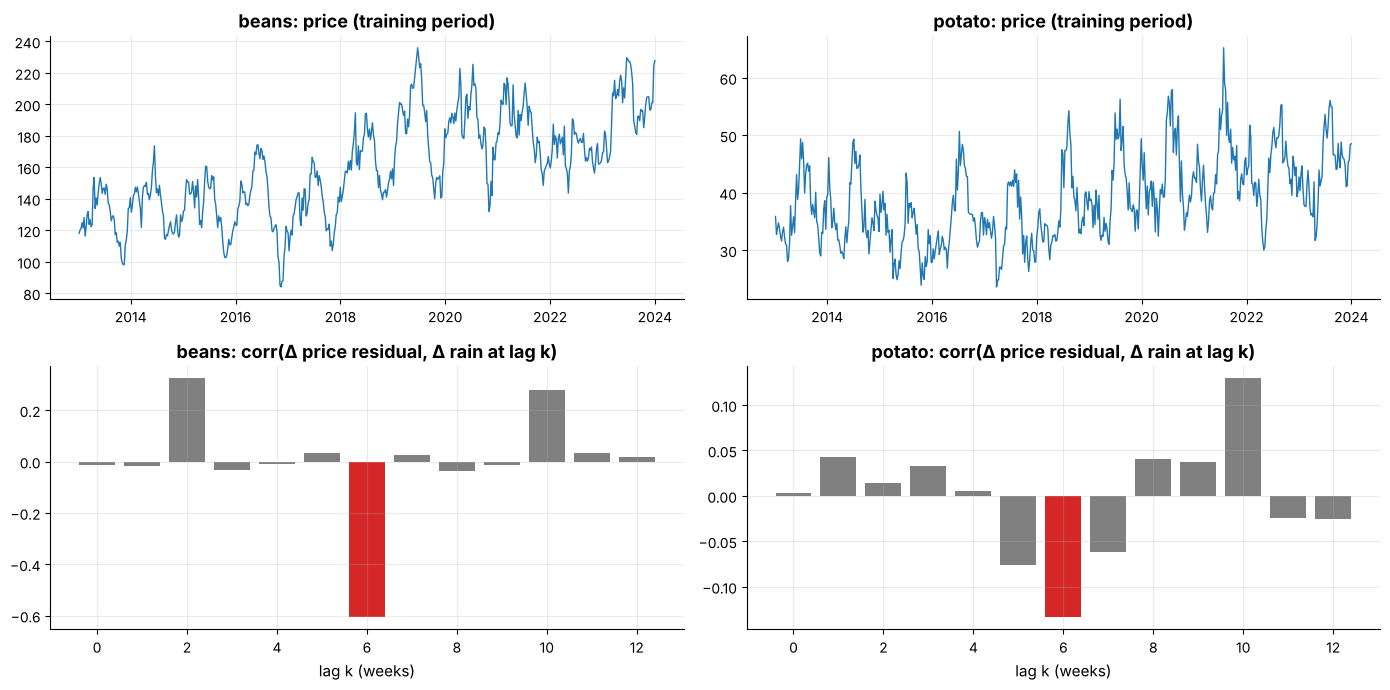

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(14, 7))
for j, (c, d) in enumerate(data.items()):
    lp = np.log(d.price); stl = STL(lp, period=52, robust=True).fit()
    ax[0, j].plot(d.price, lw=1); ax[0, j].set_title(f"{c}: price (training period)")
    # (2) lead-lag: corr between deseasonalised, detrended price changes and changes in 4-week rain, at lags 0..12
    r4 = d.rainfall_mm.rolling(4).mean().diff(); dres = stl.resid.diff()
    cc = pd.Series({k: dres.corr(r4.shift(k)) for k in range(0, 13)})
    ax[1, j].bar(cc.index, cc.values, color=["tab:red" if k == cc.abs().idxmax() else "gray" for k in cc.index])
    ax[1, j].set_title(f"{c}: corr(Δ price residual, Δ rain at lag k)"); ax[1, j].set_xlabel("lag k (weeks)")
    print(f"{c}: strongest rain lead at lag {cc.abs().idxmax()} weeks (corr {cc[cc.abs().idxmax()]:.2f})")
plt.tight_layout(); plt.show()

**Discovery 1: rainfall leads price by about 6 weeks** (strongest for beans). The bars at lags 2 and 10 are artefacts of the 4-week rolling mean. *Consequence:* a rain feature is only legitimately usable for horizons `h ≤ 6`; beyond that only older rain (lag ≥ h) is available, which carries less signal.

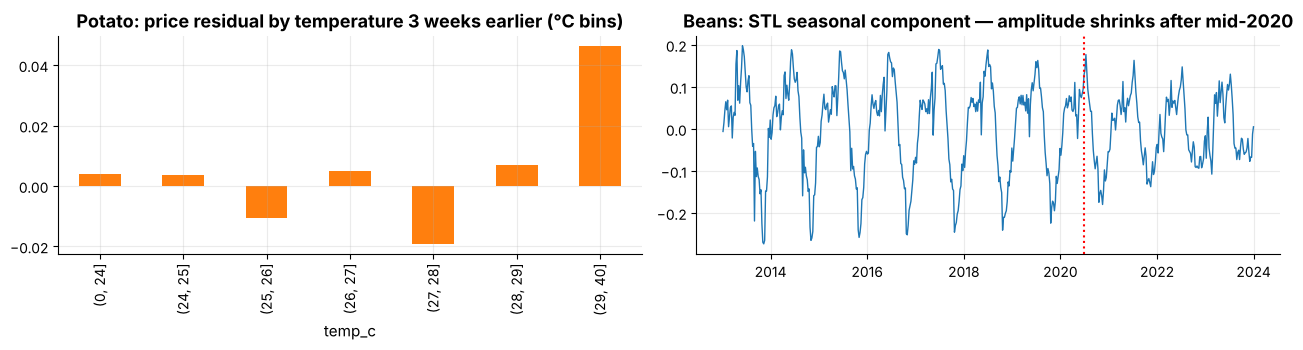

beans seasonal range  before 2020-07: 0.47 | after: 0.36


In [5]:
# (3) potato: non-linear heat effect?  deseasonalised price residual vs temperature 3 weeks earlier
d = data["potato"]; stl = STL(np.log(d.price), period=52, robust=True).fit()
dev = stl.resid - stl.resid.rolling(26, min_periods=10).mean(); t3 = d.temp_c.shift(3)
bins = pd.cut(t3, [0, 24, 25, 26, 27, 28, 29, 40])
prof = dev.groupby(bins, observed=True).agg(["mean", "count"])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
prof["mean"].plot.bar(ax=ax[0], color="tab:orange"); ax[0].set_title("Potato: price residual by temperature 3 weeks earlier (°C bins)")
# (4) beans: did seasonality change? seasonal swing before vs after mid-2020
sb = STL(np.log(data["beans"].price), period=52, robust=True).fit().seasonal
ax[1].plot(sb, lw=1); ax[1].axvline(pd.Timestamp("2020-07-01"), color="red", ls=":"); ax[1].set_title("Beans: STL seasonal component; amplitude shrinks after mid-2020")
plt.tight_layout(); plt.show()
print("beans seasonal range  before 2020-07:", round(sb[:"2020-06"].max() - sb[:"2020-06"].min(), 2), "| after:", round(sb["2020-07":].max() - sb["2020-07":].min(), 2))

**Discovery 2: potato reacts to heat only above a threshold** (~28 °C): a *non-linear* effect that a plain linear regression cannot represent but trees can.
**Discovery 3: beans' seasonal pattern weakened by roughly a quarter after mid-2020** (a structural break, e.g. a storage policy). Models trained on the full history average two regimes. A *sliding window* or a *post-break indicator* are possible remedies.
We will let the **development-period comparison** decide, not our intuitions.

## 4 · The evaluation protocol
- **Horizons:** 1, 4, 8, 12 weeks.
- **Development (dev) period:** forecast origins from the start of **2022** to the end of **2023**, every 4 weeks, refitting each time (expanding window). Used for *all* model selection.
- **Test period:** the 2024 hold-out (52 weeks) with origins every 4 weeks, run **once** with the already-selected models.
- **Leak-proof harness:** `run_walk_forward` hands each model only the past.
- **Metric:** MAE in price units (plus skill relative to naive).

## 5 · The model zoo
All models forecast on a **log scale / as returns** (Lessons 5–6). Drivers are lagged by **at least the horizon**; the rain lag is `max(h, 6)`, the exchange rate `max(h, 4)`, temperature `max(h, 3)`.

In [6]:
def features(ext, h):
    """Leak-free feature table for horizon h on an 'extended' frame (train + h empty future rows). Row t uses data <= t-h."""
    lp = np.log(ext["price"]); base = lp.shift(h)
    X = pd.DataFrame(index=ext.index)
    for k in (1, 2, 4, 8, 13, 26, 52): X[f"ret_{k}w"] = base - lp.shift(h + k)
    X["dev_ma12"] = base - lp.rolling(12).mean().shift(h)
    X["vol_13"] = lp.diff().rolling(13).std().shift(h)
    r4 = ext["rainfall_mm"].rolling(4).mean(); L = max(h, 6)
    X["rain_a"] = r4.shift(L) / 30;  X["rain_b"] = r4.shift(L + 4) / 30
    X["fx"] = np.log(ext["exchange_rate"] / 100).shift(max(h, 4))
    X["temp_l"] = ext["temp_c"].shift(max(h, 3))
    X["fest"] = ext["festival_flag"]
    return X.join(fourier_terms(ext.index, 3)), (lp - base)

def model_naive(train, h, fut):
    return train["price"].iloc[-1]

def model_snaive(train, h, fut):
    return train["price"].iloc[-52 + h - 1]                        # same week last year (h <= 52)

def ml_model(factory, recent=None):
    """Direct h-step model on log-returns. recent=N trains only on the latest N weeks (sliding window)."""
    def fn(train, h, fut):
        ext = extend(train, fut); X, y = features(ext, h)
        Xtr, ytr = X.iloc[:len(train)], y.iloc[:len(train)]
        if recent: Xtr, ytr = Xtr.iloc[-recent:], ytr.iloc[-recent:]
        ok = Xtr.notna().all(axis=1) & ytr.notna()
        m = factory().fit(Xtr[ok], ytr[ok])
        return train["price"].iloc[-1] * np.exp(float(m.predict(X.iloc[[-1]])[0]))
    return fn

def model_arimax(train, h, fut):
    """ARIMA(1,1,1) errors + Fourier terms + lagged rain/fx + festival flag, fitted on log price for THIS horizon."""
    ext = extend(train, fut); X, _ = features(ext, h)
    cols = ["sin1", "cos1", "sin2", "cos2", "sin3", "cos3", "rain_a", "fx", "fest"]
    Xe = X[cols]; ok = Xe.iloc[:len(train)].notna().all(axis=1).values
    lp = np.log(train["price"]).iloc[ok]
    res = SARIMAX(lp, exog=Xe.iloc[:len(train)][ok], order=(1, 1, 1), trend="n").fit(disp=False)
    fc = res.forecast(h, exog=Xe.iloc[len(train):len(train) + h])
    return float(np.exp(fc.iloc[-1]))

ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=30))
xgb = lambda: XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=1)
MODELS = {"naive": model_naive, "seasonal naive": model_snaive, "ARIMAX": model_arimax,
          "Ridge": ml_model(ridge), "XGBoost": ml_model(xgb), "XGBoost (last 156 wks)": ml_model(xgb, recent=156)}
print("models:", list(MODELS))

models: ['naive', 'seasonal naive', 'ARIMAX', 'Ridge', 'XGBoost', 'XGBoost (last 156 wks)']


## 6 · Development-period comparison and *per-horizon* model selection
Origins: every 4 weeks across 2022–2023. *(About a minute; each origin refits every model for every horizon.)*

In [7]:
import time
dev_wf = {}
for c, d in data.items():
    o_start = int(np.argmax(d.index >= "2022-01-01")); origins = range(o_start, len(d) - max(HORIZONS) + 1, 4)
    t0 = time.time(); w = run_walk_forward(d, MODELS, origins, verbose=False)
    w = add_blend(w, ["XGBoost", "naive"], "Blend (XGBoost + naive)")
    w = add_blend(w, ["XGBoost", "ARIMAX"], "Blend (XGBoost + ARIMAX)")
    dev_wf[c] = w; print(f"{c}: {w.origin.nunique()} dev origins, {time.time() - t0:.0f}s")
for c, w in dev_wf.items():
    print(f"\n=== {c.upper()}; DEV period MAE (lower = better) ===")
    display(scoreboard(w))

beans: 24 dev origins, 51s


potato: 24 dev origins, 51s

=== BEANS; DEV period MAE (lower = better) ===


,h=1,h=4,h=8,h=12,all,skill h=1,skill h=4,skill h=8,skill h=12,skill all
model,,,,,,,,,,
Blend (XGBoost + naive),4.377,9.756,12.186,16.527,10.711,0.187,0.268,0.052,0.141,0.156
XGBoost,4.315,7.285,13.877,20.135,11.403,0.198,0.453,-0.080,-0.047,0.102
Blend (XGBoost + ARIMAX),3.613,6.386,15.504,20.133,11.409,0.329,0.521,-0.206,-0.047,0.101
Ridge,4.714,6.950,14.620,21.580,11.966,0.124,0.478,-0.138,-0.122,0.058
XGBoost (last 156 wks),4.795,8.630,16.290,19.083,12.199,0.109,0.352,-0.267,0.008,0.039
ARIMAX,3.665,6.272,17.712,22.634,12.571,0.319,0.529,-0.378,-0.177,0.010
naive,5.382,13.322,12.853,19.232,12.697,0.000,0.000,0.000,0.000,0.000
seasonal naive,22.047,24.226,24.478,25.056,23.952,-3.096,-0.819,-0.905,-0.303,-0.886



=== POTATO; DEV period MAE (lower = better) ===


,h=1,h=4,h=8,h=12,all,skill h=1,skill h=4,skill h=8,skill h=12,skill all
model,,,,,,,,,,
Blend (XGBoost + ARIMAX),2.392,2.698,3.737,4.237,3.266,0.232,0.474,0.401,0.435,0.406
ARIMAX,2.263,2.870,3.824,4.354,3.328,0.274,0.440,0.387,0.420,0.395
Ridge,2.302,2.810,4.068,4.375,3.389,0.261,0.452,0.348,0.417,0.383
XGBoost,2.720,3.183,4.078,4.372,3.588,0.127,0.379,0.346,0.417,0.347
XGBoost (last 156 wks),2.637,3.379,4.284,4.192,3.623,0.153,0.341,0.313,0.441,0.341
Blend (XGBoost + naive),2.772,3.639,4.634,4.370,3.854,0.110,0.290,0.257,0.418,0.299
seasonal naive,3.085,4.019,4.048,4.343,3.874,0.010,0.216,0.351,0.421,0.295
naive,3.115,5.126,6.238,7.505,5.496,0.000,0.000,0.000,0.000,0.000


In [8]:
# Select the best model (baselines included) for each (commodity, horizon) using DEV results only
selected = {}
for c, w in dev_wf.items():
    t = w.groupby(["model", "h"]).apply(lambda g: mae(g.actual, g.forecast), include_groups=False).unstack("h")
    selected[c] = {int(h): t[h].idxmin() for h in t.columns}          # baselines compete too: "do nothing" can win
pd.DataFrame(selected).rename_axis("horizon (weeks)")

,beans,potato
horizon (weeks),,
1,Blend (XGBoost + ARIMAX),ARIMAX
4,ARIMAX,Blend (XGBoost + ARIMAX)
8,Blend (XGBoost + naive),Blend (XGBoost + ARIMAX)
12,Blend (XGBoost + naive),XGBoost (last 156 wks)


> 🧠 **Why per-horizon selection?** Different information is usable at different horizons: rain (lag ≥ 6) helps at h ≤ 6, momentum at short ranges, seasonality at long ones. One model is rarely best everywhere.
> And note what we *did not* do: look at 2024.

## 7 · The one-shot test on the 2024 hold-out
Only now do we open `project_market_holdout_2024.csv`. We append it to the cleaned training data, and evaluate with origins every 4 weeks through 2024: each origin sees only the weeks before it (the harness enforces this).
We run the **selected** model for each (commodity, horizon), plus the naive baseline.

In [9]:
hold = pd.read_csv("../project/data/project_market_holdout_2024.csv", parse_dates=["date"])
test_wf = {}
for c, d_tr in data.items():
    d_all = pd.concat([d_tr, hold[hold.commodity == c].drop(columns="commodity").set_index("date")]); d_all.index.freq = "W-SUN"
    o_start = int(np.argmax(d_all.index >= "2024-01-01")); origins = range(o_start, len(d_all) - max(HORIZONS) + 1, 4)
    need = sorted(set(selected[c].values()) | {"naive"})
    base_names = [m for m in need if m in MODELS]
    w = run_walk_forward(d_all, {m: MODELS[m] for m in base_names + ["XGBoost", "ARIMAX"] if m in MODELS}, origins, verbose=False)
    w = add_blend(w, ["XGBoost", "naive"], "Blend (XGBoost + naive)"); w = add_blend(w, ["XGBoost", "ARIMAX"], "Blend (XGBoost + ARIMAX)")
    test_wf[c] = w
rows = []
for c, w in test_wf.items():
    for h in HORIZONS:
        g = w[w.h == h]; sel = selected[c][h]
        m_sel = mae(g[g.model == sel].actual, g[g.model == sel].forecast); m_nv = mae(g[g.model == "naive"].actual, g[g.model == "naive"].forecast)
        rows.append(dict(commodity=c, horizon=h, selected_model=sel, test_MAE=m_sel, naive_MAE=m_nv, skill=1 - m_sel / m_nv))
final = pd.DataFrame(rows); print(f"2024 hold-out ({test_wf['beans'].origin.nunique()} origins per commodity): selected model vs naive")
final.round(2)

2024 hold-out (11 origins per commodity): selected model vs naive


,commodity,horizon,selected_model,test_MAE,naive_MAE,skill
0,beans,1,Blend (XGBoost + ARIMAX),4.63,7.71,0.40
1,beans,4,ARIMAX,9.90,9.49,-0.04
2,beans,8,Blend (XGBoost + naive),19.01,15.83,-0.20
3,beans,12,Blend (XGBoost + naive),21.99,21.17,-0.04
4,potato,1,ARIMAX,2.18,1.48,-0.48
5,potato,4,Blend (XGBoost + ARIMAX),3.12,4.97,0.37
6,potato,8,Blend (XGBoost + ARIMAX),2.69,8.62,0.69
7,potato,12,XGBoost (last 156 wks),4.04,11.55,0.65


In [10]:
# Context: how would EVERY candidate have done on the hold-out? (for the report: NOT for re-selecting!)
for c, w in test_wf.items():
    print(f"\n=== {c.upper()}: hold-out MAE by model (information only; selection was already made) ===")
    display(scoreboard(w))


=== BEANS: hold-out MAE by model (information only; selection was already made) ===


,h=1,h=4,h=8,h=12,all,skill h=1,skill h=4,skill h=8,skill h=12,skill all
model,,,,,,,,,,
Blend (XGBoost + naive),5.316,6.145,19.015,21.989,13.116,0.311,0.352,-0.201,-0.039,0.032
naive,7.712,9.486,15.832,21.171,13.550,0.000,0.000,0.000,0.000,0.000
Blend (XGBoost + ARIMAX),4.627,8.306,20.093,25.642,14.667,0.400,0.124,-0.269,-0.211,-0.082
ARIMAX,5.061,9.900,20.278,25.078,15.079,0.344,-0.044,-0.281,-0.185,-0.113
XGBoost,4.923,8.646,22.198,26.914,15.670,0.362,0.089,-0.402,-0.271,-0.156



=== POTATO: hold-out MAE by model (information only; selection was already made) ===


,h=1,h=4,h=8,h=12,all,skill h=1,skill h=4,skill h=8,skill h=12,skill all
model,,,,,,,,,,
ARIMAX,2.178,3.017,2.620,3.427,2.811,-0.476,0.392,0.696,0.703,0.578
Blend (XGBoost + ARIMAX),2.301,3.118,2.690,3.216,2.831,-0.559,0.372,0.688,0.721,0.574
XGBoost,2.800,3.247,2.969,3.695,3.178,-0.898,0.346,0.656,0.680,0.522
XGBoost (last 156 wks),2.340,3.803,3.509,4.041,3.423,-0.586,0.234,0.593,0.650,0.485
Blend (XGBoost + naive),2.059,3.644,5.535,7.270,4.627,-0.396,0.266,0.358,0.370,0.304
naive,1.475,4.966,8.624,11.545,6.653,0.000,0.000,0.000,0.000,0.000


## 8 · Uncertainty: empirical prediction intervals
A forecast without a range is a guess. We learn the spread of **log forecast errors per horizon on the dev period only**, then check **coverage** on the hold-out (a nominal 80 % interval should contain ≈ 80 % of the actuals).

In [11]:
cov_rows = []
for c in data:
    for h in HORIZONS:
        sel = selected[c][h]
        q = empirical_interval(dev_wf[c][dev_wf[c].h == h], sel, alpha=0.2)
        cov_rows.append(dict(commodity=c, horizon=h, model=sel, coverage_80=coverage(test_wf[c][test_wf[c].h == h], sel, q)))
cov = pd.DataFrame(cov_rows); display(cov.round(2))

,commodity,horizon,model,coverage_80
0,beans,1,Blend (XGBoost + ARIMAX),0.73
1,beans,4,ARIMAX,0.64
2,beans,8,Blend (XGBoost + naive),0.36
3,beans,12,Blend (XGBoost + naive),0.64
4,potato,1,ARIMAX,0.82
5,potato,4,Blend (XGBoost + ARIMAX),0.64
6,potato,8,Blend (XGBoost + ARIMAX),0.91
7,potato,12,XGBoost (last 156 wks),0.91


## 9 · Conclusions (the model card)
**Setting:** two commodities, horizons 1/4/8/12 weeks, model chosen per commodity *and* horizon on the 2022–23 development period, then tested once on 2024 (11 forecast origins per commodity).

**Potato: forecasting works.** At 4, 8 and 12 weeks ahead the selected models cut the naive MAE by roughly **40 %, 70 % and 65 %**. At h = 1 the naive forecast is very hard to beat (the model was better on the dev period but *worse* on the 2024 hold-out: with 11 origins, a short-horizon difference of ≈ 1 price unit is largely noise).
*Why it works:* potato has a strong, stable seasonal shape plus lagged weather/currency effects, and a *non-linear* heat effect that tree models and ARIMAX-with-lags capture partly.

**Beans: much harder.** The selected models help at **h = 1** (≈ 40 % lower MAE) but are **not better than naive at h = 4, 8 and 12**. The 2024 hold-out contains the price impact of a drought that began in September 2023; that impact arrives with a lag of ~6 weeks, so most of it falls *inside* the hold-out and was barely visible in the development period. On top of that the market's seasonality had changed structurally in 2020, so models trained on the full history blend two seasonal regimes. A model that must forecast a shock it has barely seen, from drivers that only act with a delay, is fragile, which is what we observe. Shrinking XGBoost halfway towards naive (the blend) was the most robust beans model overall.

**Uncertainty.** Empirical 80 % intervals learned on the dev period are reasonably calibrated for potato (≈ 0.6–0.9 coverage) but too narrow for beans at long horizons (0.36 at h = 8): the hold-out shock was outside the dev error distribution: intervals are only as good as the stability of the world they were learned in.

**Recommendation.**
1. **Potato:** deploy the ARIMAX/XGBoost blend for horizons ≥ 4 weeks; use the naive forecast for next-week.
2. **Beans:** use the model only for short horizons (≤ 4 weeks); for 8–12 weeks publish the naive/blend forecast with *wide* intervals and flag weather risk explicitly.
3. Retrain every few weeks; monitor errors for regime change.

**Limitations.** 11 test origins per commodity (differences of a few percent are noise); per-horizon selection on 24 dev origins is itself noisy; no post-break indicator or intervention model was tried for beans; weather forecasts (rather than lagged observations) could extend the useful horizon of the rain driver.

**Next experiments.** (a) a *regime indicator* or training only on post-2020 data for beans; (b) a global model across both commodities; (c) quantile/conformal intervals refreshed regularly; (d) feeding *forecast* rainfall (e.g. seasonal outlooks) into the models.